# 🚲 Bike Rental Demand Prediction Using Machine Learning
### Third Year (TY) Computer Engineering Mini Project

---

## 🎯 Project Overview & Problem Statement
Urban bike-sharing systems offer an eco-friendly and affordable mobility solution. However, fluctuating demand creates operational bottlenecks—such as dock shortages at transit hubs during peak hours and excess idle bikes in residential areas. 

**Objective:**
Build an end-to-end supervised machine learning regression pipeline to predict hourly bike rental counts (`cnt`) from weather, atmospheric, and calendar attributes.

**Algorithms Evaluated:**
1. **Linear Regression** (Baseline)
2. **K-Nearest Neighbors (KNN) Regressor**
3. **Decision Tree Regressor**
4. **Random Forest Regressor** (Ensemble Bagging)
5. **Gradient Boosting Regressor** (Ensemble Boosting)

---


### Step 1: Library Imports & Environment Configuration
We load standard data science libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`) and Scikit-Learn modules for preprocessing, pipelining, and evaluation.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn Modules
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Regression Models
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Visual Styling
sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
%matplotlib inline

print("✅ All required libraries imported successfully!")


✅ All required libraries imported successfully!


### Step 2: Data Loading & Initial Inspection
We load `data/hour.csv` from the Capital Bikeshare / UCI Machine Learning repository and inspect its shape, columns, summary statistics, missing values, and duplicate rows.

In [2]:
# Load hourly dataset
df = pd.read_csv('data/hour.csv')

print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nFirst 5 rows:")
df.head()


Dataset Dimensions: 17379 rows, 17 columns

First 5 rows:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [3]:
# Dataset schema and data types
print("--- Dataset Information ---")
df.info()


--- Dataset Information ---
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.4 MB


In [4]:
# Statistical summary of numerical features
df.describe().round(3)


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000
mean,8690.000,2.502,0.503,6.538,11.547,0.029,3.004,0.683,1.425,0.497,0.476,0.627,0.190,35.676,153.787,189.463
std,5017.029,1.107,0.500,3.439,6.914,0.167,2.006,0.465,0.639,0.193,0.172,0.193,0.122,49.305,151.357,181.388
min,1.000,1.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.020,0.000,0.000,0.000,0.000,0.000,1.000
25%,4345.500,2.000,0.000,4.000,6.000,0.000,1.000,0.000,1.000,0.340,0.333,0.480,0.104,4.000,34.000,40.000
50%,8690.000,3.000,1.000,7.000,12.000,0.000,3.000,1.000,1.000,0.500,0.485,0.630,0.194,17.000,115.000,142.000
75%,13034.500,3.000,1.000,10.000,18.000,0.000,5.000,1.000,2.000,0.660,0.621,0.780,0.254,48.000,220.000,281.000
max,17379.000,4.000,1.000,12.000,23.000,1.000,6.000,1.000,4.000,1.000,1.000,1.000,0.851,367.000,886.000,977.000


In [5]:
# Check for missing values and duplicates
missing_count = df.isnull().sum().sum()
duplicate_count = df.duplicated().sum()

print(f"Total Missing Values: {missing_count}")
print(f"Total Duplicate Rows: {duplicate_count}")


Total Missing Values: 0
Total Duplicate Rows: 0


---
## 📊 Step 3: Exploratory Data Analysis (EDA)
EDA helps us discover seasonal trends, diurnal commuter patterns, weather sensitivities, and feature correlations before training machine learning models.


#### 1. Average Bike Rentals by Hour of the Day (0 to 23)

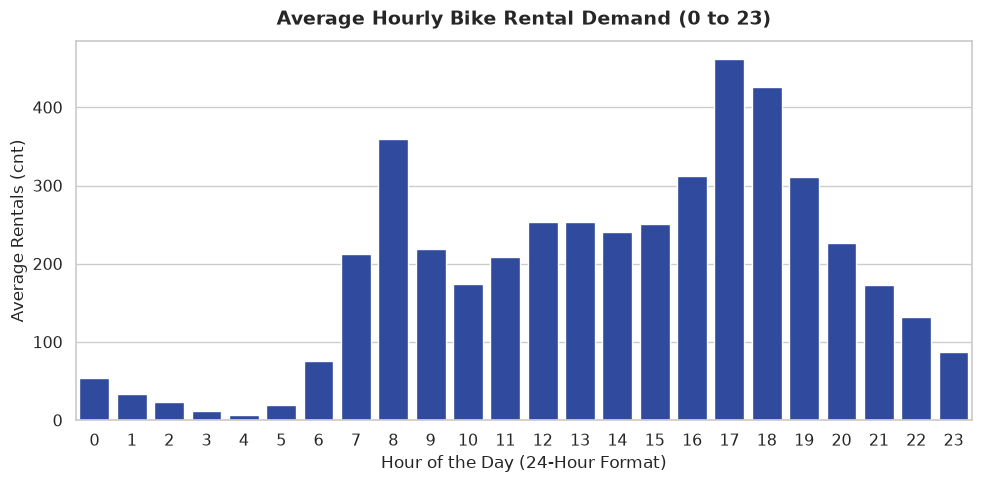

💡 Insight: Demand exhibits prominent twin peaks at 8:00 AM (morning rush) and 5:00-6:00 PM (evening commute).


In [6]:
plt.figure(figsize=(10, 5))
hourly_avg = df.groupby('hr')['cnt'].mean().reset_index()
sns.barplot(data=hourly_avg, x='hr', y='cnt', color='#1E40AF')
plt.title('Average Hourly Bike Rental Demand (0 to 23)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Hour of the Day (24-Hour Format)', fontsize=12)
plt.ylabel('Average Rentals (cnt)', fontsize=12)
plt.tight_layout()
plt.show()

# One-line insight:
print("💡 Insight: Demand exhibits prominent twin peaks at 8:00 AM (morning rush) and 5:00-6:00 PM (evening commute).")


#### 2. Bike Rentals Across Seasons

C:\Users\Rutikesh\AppData\Local\Temp\ipykernel_21888\3125783292.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_temp, x='season_name', y='cnt', order=['Spring', 'Summer', 'Fall', 'Winter'], palette='Set2')


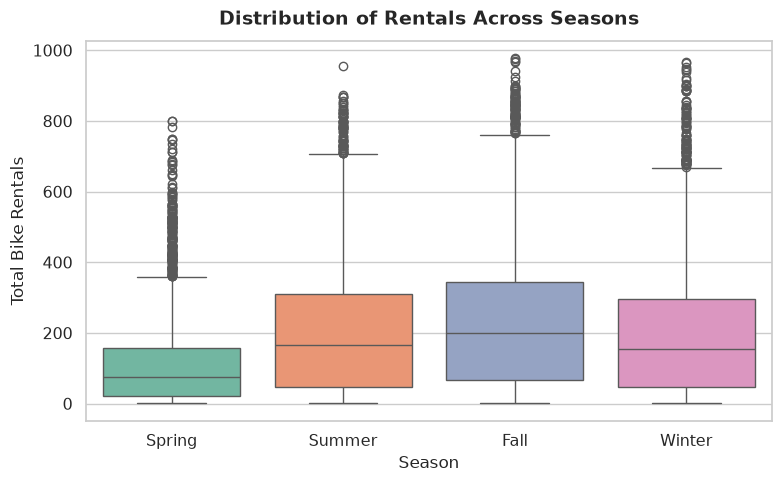

💡 Insight: Fall and Summer experience peak rental volumes, whereas Spring experiences significantly reduced usage due to cold conditions.


In [7]:
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
df_temp = df.copy()
df_temp['season_name'] = df_temp['season'].map(season_map)

plt.figure(figsize=(8, 5))
sns.boxplot(data=df_temp, x='season_name', y='cnt', order=['Spring', 'Summer', 'Fall', 'Winter'], palette='Set2')
plt.title('Distribution of Rentals Across Seasons', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Season', fontsize=12)
plt.ylabel('Total Bike Rentals', fontsize=12)
plt.tight_layout()
plt.show()

# One-line insight:
print("💡 Insight: Fall and Summer experience peak rental volumes, whereas Spring experiences significantly reduced usage due to cold conditions.")


#### 3. Bike Rentals by Weather Condition

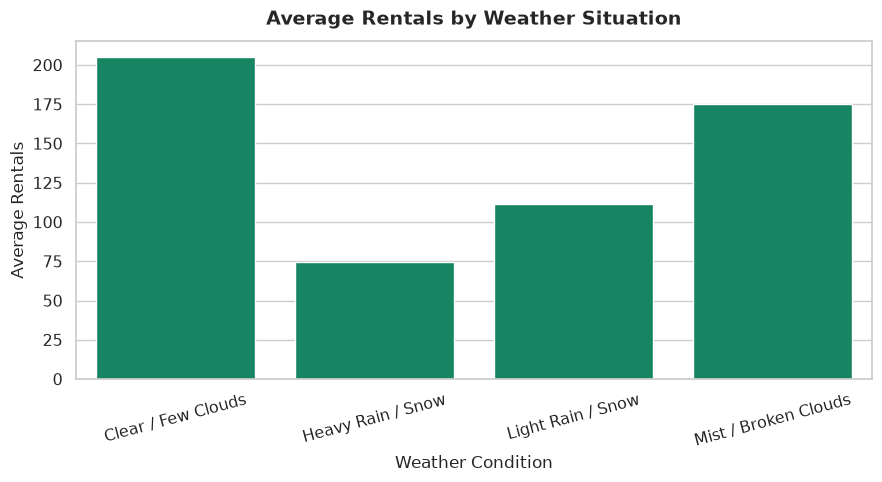

💡 Insight: Clear weather yields peak rentals (~205/hr), dropping by nearly 50% during light rain/snow and >65% in severe storms.


In [8]:
weather_map = {
    1: 'Clear / Few Clouds',
    2: 'Mist / Broken Clouds',
    3: 'Light Rain / Snow',
    4: 'Heavy Rain / Snow'
}
df_temp['weather_name'] = df_temp['weathersit'].map(weather_map)

plt.figure(figsize=(9, 5))
weather_avg = df_temp.groupby('weather_name')['cnt'].mean().reset_index()
sns.barplot(data=weather_avg, x='weather_name', y='cnt', color='#059669')
plt.title('Average Rentals by Weather Situation', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Weather Condition', fontsize=12)
plt.ylabel('Average Rentals', fontsize=12)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# One-line insight:
print("💡 Insight: Clear weather yields peak rentals (~205/hr), dropping by nearly 50% during light rain/snow and >65% in severe storms.")


#### 4. Diurnal Demand Pattern: Working Day vs. Weekend / Holiday

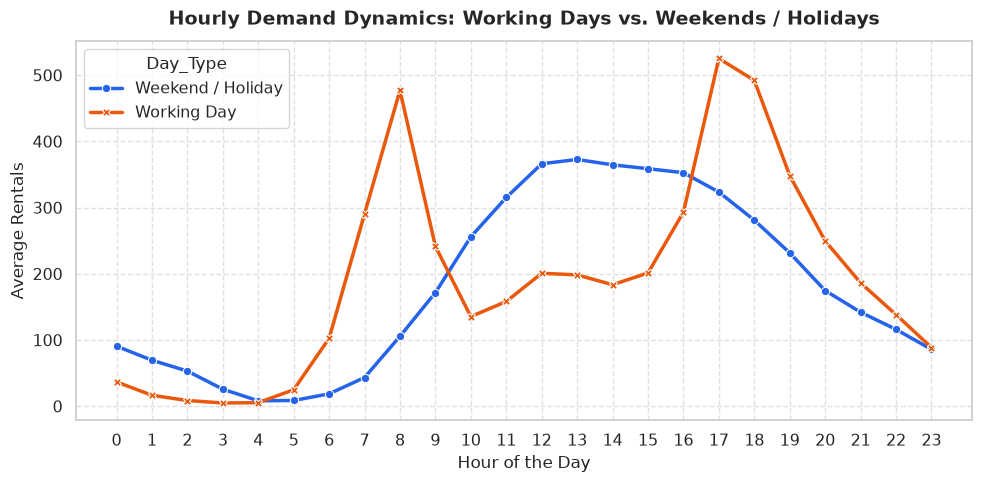

💡 Insight: Working days show sharp commuter commute spikes (8 AM & 5 PM), whereas holidays and weekends follow a unimodal leisure curve peaking at 1-3 PM.


In [9]:
df_temp['Day_Type'] = df_temp['workingday'].map({1: 'Working Day', 0: 'Weekend / Holiday'})
hourly_day = df_temp.groupby(['hr', 'Day_Type'])['cnt'].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=hourly_day, x='hr', y='cnt', hue='Day_Type', style='Day_Type', markers=True, dashes=False, linewidth=2.5, palette=['#2563EB', '#EA580C'])
plt.title('Hourly Demand Dynamics: Working Days vs. Weekends / Holidays', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Hour of the Day', fontsize=12)
plt.ylabel('Average Rentals', fontsize=12)
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# One-line insight:
print("💡 Insight: Working days show sharp commuter commute spikes (8 AM & 5 PM), whereas holidays and weekends follow a unimodal leisure curve peaking at 1-3 PM.")


#### 5. Correlation Heatmap Between Numeric Features and Rentals

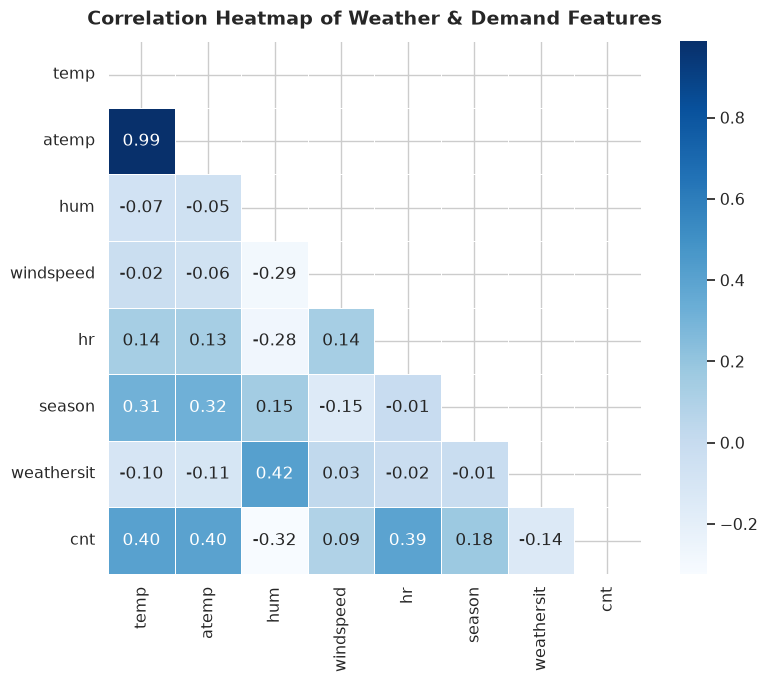

💡 Insight: Temperature (+0.40) and hour (+0.39) have strong positive correlations with rentals, while humidity (-0.32) exerts an inverse drag.


In [10]:
corr_cols = ['temp', 'atemp', 'hum', 'windspeed', 'hr', 'season', 'weathersit', 'cnt']
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(9, 7))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='Blues', square=True, linewidths=0.5)
plt.title('Correlation Heatmap of Weather & Demand Features', fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

# One-line insight:
print("💡 Insight: Temperature (+0.40) and hour (+0.39) have strong positive correlations with rentals, while humidity (-0.32) exerts an inverse drag.")


#### 6. Temperature vs. Bike Rentals Scatter Plot

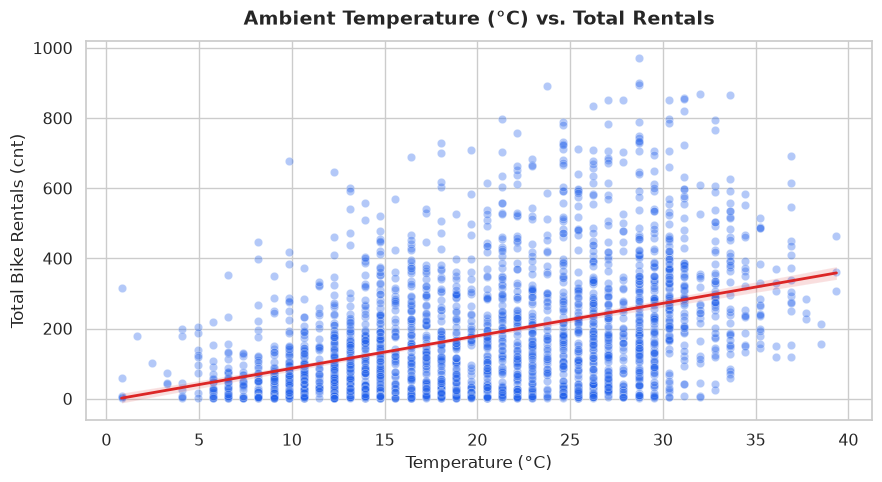

💡 Insight: Bike rentals grow steadily with warmer temperatures up to ~30°C, after which extreme heat plateaus demand.


In [11]:
# Denormalize temperature to Celsius (temp * 41) for intuitive interpretation
sample_df = df.sample(n=2500, random_state=42).copy()
sample_df['temp_celsius'] = sample_df['temp'] * 41

plt.figure(figsize=(9, 5))
sns.scatterplot(data=sample_df, x='temp_celsius', y='cnt', alpha=0.35, color='#2563EB')
sns.regplot(data=sample_df, x='temp_celsius', y='cnt', scatter=False, color='#DC2626', line_kws={'linewidth': 2})
plt.title('Ambient Temperature (°C) vs. Total Rentals', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Temperature (°C)', fontsize=12)
plt.ylabel('Total Bike Rentals (cnt)', fontsize=12)
plt.tight_layout()
plt.show()

# One-line insight:
print("💡 Insight: Bike rentals grow steadily with warmer temperatures up to ~30°C, after which extreme heat plateaus demand.")


---
## ⚙️ Step 4: Data Preprocessing & Leakage Prevention

### Preventing Data Leakage
In the original dataset:
- `casual`: Rentals by non-registered casual users
- `registered`: Rentals by subscribed registered users
- `cnt`: Total rentals = `casual + registered`

> **Crucial Rule:** Keeping `casual` and `registered` causes severe **data leakage**, because in real-world deployment we never know the breakdown ahead of time. Keeping them allows a model to simply compute their sum.
> We also drop `instant` (index) and `dteday` (date string superseded by `yr`, `mnth`, and `weekday`).


In [12]:
# 1. Drop leakage and identifier columns
leakage_cols = ['instant', 'dteday', 'casual', 'registered']
df_clean = df.drop(columns=leakage_cols)

# 2. Separate Features (X) and Target (y)
X = df_clean.drop(columns=['cnt'])
y = df_clean['cnt']

print(f"Features DataFrame Shape: {X.shape}")
print(f"Target Series Shape: {y.shape}")
print(f"Feature Names: {list(X.columns)}")


Features DataFrame Shape: (17379, 12)
Target Series Shape: (17379,)
Feature Names: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']


### Train / Test Split (80% Train, 20% Test)
We split using `random_state=42` to guarantee exact reproducibility across all machines.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training set: {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Testing set:  {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.1f}%)")


Training set: 13903 samples (80.0%)
Testing set:  3476 samples (20.0%)


### Feature Transformation Pipeline with `ColumnTransformer`
- **Categorical Columns** (`season`, `yr`, `mnth`, `hr`, `holiday`, `weekday`, `workingday`, `weathersit`): Transformed via `OneHotEncoder(handle_unknown='ignore')` so models do not treat integers as numerical orders.
- **Continuous Numerical Columns** (`temp`, `atemp`, `hum`, `windspeed`): Normalized via `StandardScaler()` (crucial for distance/linear models like KNN and Linear Regression).


In [14]:
categorical_cols = ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit']
numeric_cols = ['temp', 'atemp', 'hum', 'windspeed']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols),
        ('num', StandardScaler(), numeric_cols)
    ]
)

print("✅ ColumnTransformer pipeline successfully defined!")


✅ ColumnTransformer pipeline successfully defined!


---
## 🤖 Step 5: Model Training with Scikit-Learn Pipelines
We instantiate 5 regression models embedded inside Scikit-Learn `Pipeline` objects to ensure no data leakage occurs between training folds and test sets.


In [15]:
models = {
    'Linear Regression': Pipeline([
        ('prep', preprocessor),
        ('reg', LinearRegression())
    ]),
    'KNN Regressor': Pipeline([
        ('prep', preprocessor),
        ('reg', KNeighborsRegressor(n_neighbors=5))
    ]),
    'Decision Tree': Pipeline([
        ('prep', preprocessor),
        ('reg', DecisionTreeRegressor(random_state=42, max_depth=15))
    ]),
    'Random Forest': Pipeline([
        ('prep', preprocessor),
        ('reg', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
    ]),
    'Gradient Boosting': Pipeline([
        ('prep', preprocessor),
        ('reg', GradientBoostingRegressor(n_estimators=100, random_state=42, learning_rate=0.1))
    ])
}

# Dictionary to store fitted models and test predictions
fitted_models = {}
predictions = {}

print("Training all 5 regression models...")
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    # Clip predictions at 0 because rental counts cannot be negative
    y_pred = np.maximum(0, pipeline.predict(X_test))
    
    fitted_models[name] = pipeline
    predictions[name] = y_pred
    print(f"  ✓ {name} fitted successfully")


Training all 5 regression models...
  ✓ Linear Regression fitted successfully


  ✓ KNN Regressor fitted successfully
  ✓ Decision Tree fitted successfully


  ✓ Random Forest fitted successfully


  ✓ Gradient Boosting fitted successfully


---
## 📈 Step 6: Model Evaluation & Benchmark Comparison
We evaluate all models on unseen test data using:
1. **MAE (Mean Absolute Error):** Average magnitude of errors in bike units.
2. **RMSE (Root Mean Squared Error):** Penalizes larger outlier prediction errors.
3. **R² Score (Coefficient of Determination):** Proportion of variance explained (higher is better, max 1.0).


In [16]:
evaluation_results = []

for name, y_pred in predictions.items():
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    evaluation_results.append({
        'Model': name,
        'MAE (Bikes)': round(mae, 2),
        'RMSE (Bikes)': round(rmse, 2),
        'R² Score': round(r2, 4)
    })

results_df = pd.DataFrame(evaluation_results).sort_values(by='R² Score', ascending=False).reset_index(drop=True)
print("=== Model Comparison Table on Test Data ===")
display(results_df)


=== Model Comparison Table on Test Data ===


,Model,MAE (Bikes),RMSE (Bikes),R² Score
0,Random Forest,29.79,47.83,0.9277
1,Gradient Boosting,57.39,79.74,0.7992
2,Decision Tree,52.95,80.71,0.7943
3,Linear Regression,69.22,97.75,0.6982
4,KNN Regressor,74.77,108.50,0.6283


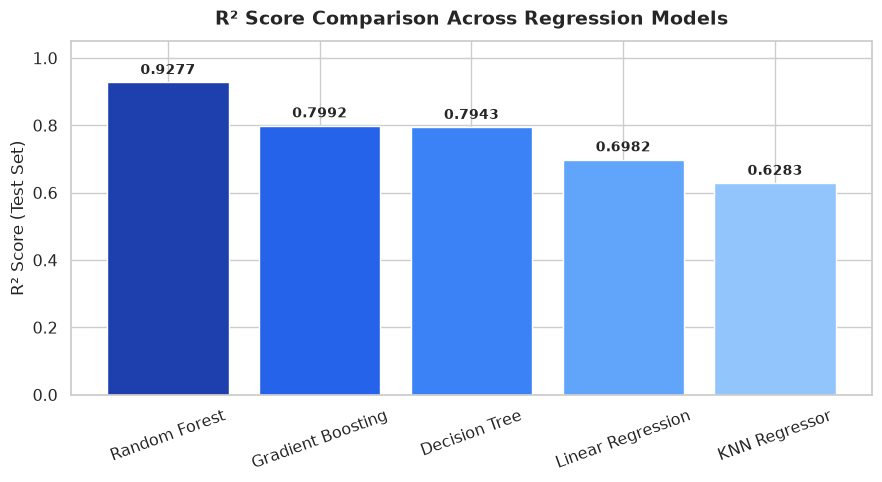

In [17]:
plt.figure(figsize=(9, 5))
bars = plt.bar(results_df['Model'], results_df['R² Score'], color=['#1E40AF', '#2563EB', '#3B82F6', '#60A5FA', '#93C5FD'])
plt.title('R² Score Comparison Across Regression Models', fontsize=14, fontweight='bold', pad=12)
plt.ylabel('R² Score (Test Set)', fontsize=12)
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.015, f'{yval:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=10)
plt.tight_layout()
plt.show()


### Actual vs. Predicted & Residual Analysis (Random Forest)

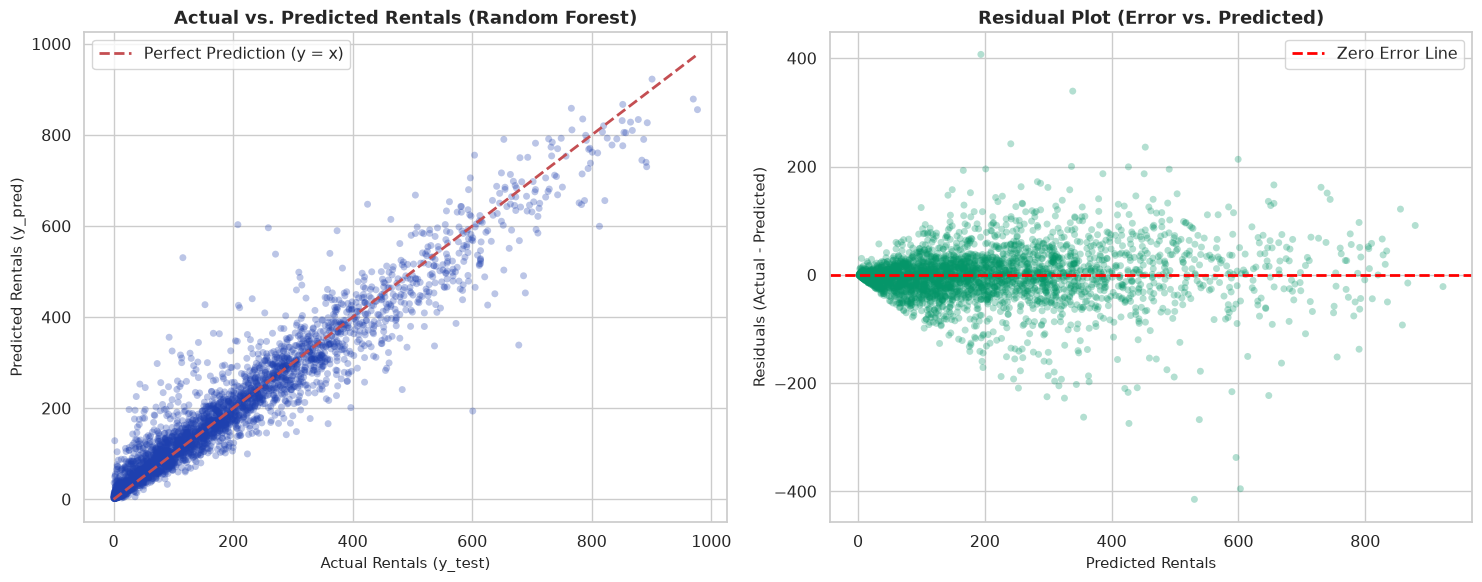

In [18]:
best_model_name = 'Random Forest'
best_preds = predictions[best_model_name]
residuals = y_test - best_preds

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Actual vs Predicted
axes[0].scatter(y_test, best_preds, alpha=0.3, color='#1E40AF', edgecolors='none', s=25)
max_val = max(y_test.max(), best_preds.max())
axes[0].plot([0, max_val], [0, max_val], 'r--', linewidth=2, label='Perfect Prediction (y = x)')
axes[0].set_title(f'Actual vs. Predicted Rentals ({best_model_name})', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Actual Rentals (y_test)', fontsize=11)
axes[0].set_ylabel('Predicted Rentals (y_pred)', fontsize=11)
axes[0].legend(frameon=True)

# Plot 2: Residual Plot
axes[1].scatter(best_preds, residuals, alpha=0.3, color='#059669', edgecolors='none', s=25)
axes[1].axhline(0, color='red', linestyle='--', linewidth=2, label='Zero Error Line')
axes[1].set_title('Residual Plot (Error vs. Predicted)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Predicted Rentals', fontsize=11)
axes[1].set_ylabel('Residuals (Actual - Predicted)', fontsize=11)
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()


---
## 🔍 Step 7: Hyperparameter Tuning with GridSearchCV
We perform 5-fold cross-validation on our champion algorithm (**Random Forest Regressor**) to optimize tree depth, number of estimators, and sample split parameters.


In [19]:
param_grid = {
    'reg__n_estimators': [100, 150],
    'reg__max_depth': [20, None],
    'reg__min_samples_split': [2, 5]
}

grid_search = GridSearchCV(
    estimator=Pipeline([
        ('prep', preprocessor),
        ('reg', RandomForestRegressor(random_state=42, n_jobs=-1))
    ]),
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

print("Starting 5-Fold Cross-Validation Grid Search...")
grid_search.fit(X_train, y_train)

best_tuned_model = grid_search.best_estimator_
y_pred_tuned = np.maximum(0, best_tuned_model.predict(X_test))

print(f"\n🏆 Best Hyperparameters: {grid_search.best_params_}")
print(f"5-Fold CV Best R² Score: {grid_search.best_score_:.4f}")
print(f"Tuned Test Set R² Score: {r2_score(y_test, y_pred_tuned):.4f}")
print(f"Tuned Test Set MAE:      {mean_absolute_error(y_test, y_pred_tuned):.2f} bikes")
print(f"Tuned Test Set RMSE:     {np.sqrt(mean_squared_error(y_test, y_pred_tuned)):.2f} bikes")


Starting 5-Fold Cross-Validation Grid Search...
Fitting 5 folds for each of 8 candidates, totalling 40 fits



🏆 Best Hyperparameters: {'reg__max_depth': None, 'reg__min_samples_split': 2, 'reg__n_estimators': 100}
5-Fold CV Best R² Score: 0.9193
Tuned Test Set R² Score: 0.9277
Tuned Test Set MAE:      29.79 bikes
Tuned Test Set RMSE:     47.83 bikes


---
## 🌟 Step 8: Feature Importance Analysis
We extract the Gini impurity reduction from the tuned Random Forest model across all transformed one-hot and numerical features.


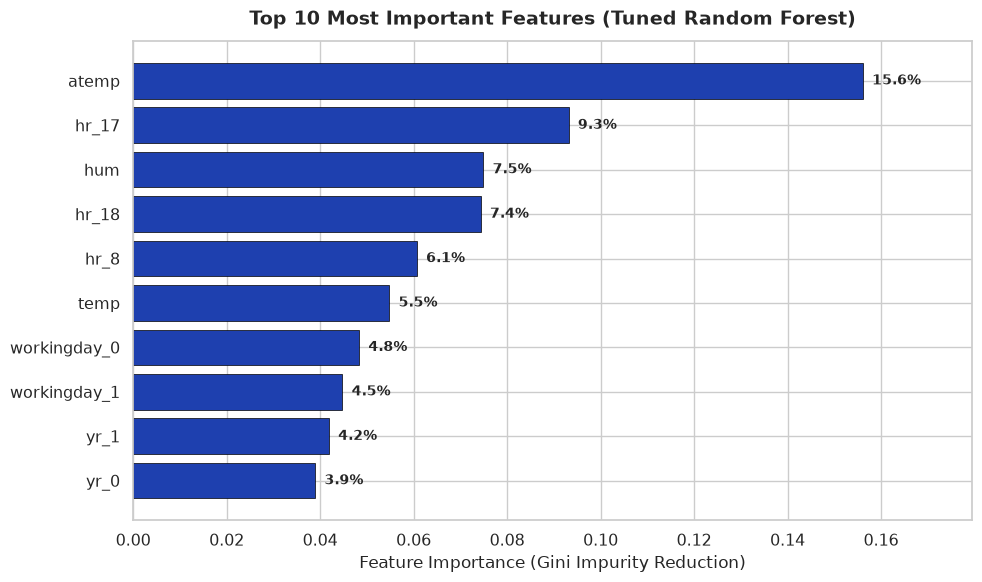


Top 5 Drivers of Demand:
  atemp                -> 15.61% contribution
  hr_17                -> 9.32% contribution
  hum                  -> 7.49% contribution
  hr_18                -> 7.43% contribution
  hr_8                 -> 6.07% contribution


In [20]:
# Extract feature names from OneHotEncoder + numeric columns
preprocessor_fitted = best_tuned_model.named_steps['prep']
rf_fitted = best_tuned_model.named_steps['reg']

ohe = preprocessor_fitted.named_transformers_['cat']
cat_feature_names = list(ohe.get_feature_names_out(categorical_cols))
all_features = cat_feature_names + numeric_cols

# Create DataFrame of importances
feat_importances = pd.DataFrame({
    'Feature': all_features,
    'Importance': rf_fitted.feature_importances_
}).sort_values(by='Importance', ascending=False)

top10_features = feat_importances.head(10).iloc[::-1]

# Plot horizontal bar chart
plt.figure(figsize=(10, 6))
bars = plt.barh(top10_features['Feature'], top10_features['Importance'], color='#1E40AF', edgecolor='black', linewidth=0.5)
plt.title('Top 10 Most Important Features (Tuned Random Forest)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Feature Importance (Gini Impurity Reduction)', fontsize=12)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.002, bar.get_y() + bar.get_height()/2, f'{w*100:.1f}%', va='center', fontsize=10, fontweight='bold')

plt.xlim(0, max(top10_features['Importance']) * 1.15)
plt.tight_layout()
plt.show()

print("\nTop 5 Drivers of Demand:")
for idx, row in feat_importances.head(5).iterrows():
    print(f"  {row['Feature']:20} -> {row['Importance']*100:.2f}% contribution")


---
## 💾 Step 9: Save Final Model Pipeline with Joblib
We serialize the entire pipeline (preprocessor + tuned Random Forest) to `models/bike_model.pkl`. This encapsulates all encoding parameters and weights into a single production asset.


In [21]:
os.makedirs('models', exist_ok=True)
model_filepath = 'models/bike_model.pkl'

joblib.dump(best_tuned_model, model_filepath)
print(f"✅ Final model pipeline successfully saved to '{model_filepath}'")
print(f"File size: {os.path.getsize(model_filepath) / (1024*1024):.2f} MB")


✅ Final model pipeline successfully saved to 'models/bike_model.pkl'
File size: 114.81 MB


---
## 🧪 Step 10: Verification with `predict_demand` Function
We verify our saved model pipeline by loading it back and running an end-to-end sample test with realistic user values.


In [22]:
from predict import predict_demand

# Sample test: A pleasant summer Monday morning at 8:00 AM
test_input = {
    'season': 2,        # Summer
    'yr': 1,            # 2012
    'mnth': 6,          # June
    'hr': 8,            # 8:00 AM
    'holiday': 0,       # Not a holiday
    'weekday': 1,       # Monday
    'workingday': 1,    # Working day
    'weathersit': 1,    # Clear skies
    'temp': 26.0,       # 26°C
    'atemp': 27.0,      # Feeling 27°C
    'hum': 48.0,        # 48% humidity
    'windspeed': 10.0   # 10 km/h
}

prediction = predict_demand(test_input)

print("=== Prediction Result ===")
print(f"Input: Monday 8:00 AM, Summer, Clear Skies, 26°C")
print(f"Predicted Rentals:    {prediction['predicted_count']} bikes")
print(f"Demand Category:      {prediction['demand_level']}")
print(f"Expected 95% Window:  {prediction['confidence_interval_low']} to {prediction['confidence_interval_high']} bikes")


=== Prediction Result ===
Input: Monday 8:00 AM, Summer, Clear Skies, 26°C
Predicted Rentals:    638 bikes
Demand Category:      Peak
Expected 95% Window:  591 to 685 bikes
